# Adaptive baseline mortality

This notebook produces **Manuscript Figure 3** and the all-age extension referenced as **Supplementary Figure 9**. It compares weekly registered deaths with the adaptive baseline estimated after subtracting modeled weather- and respiratory-infection-associated components.

The baseline is an age- and sex-specific, slowly varying component of the fitted decomposition. It should not be interpreted as a directly observed exposure-free mortality level. The first figure displays selected age groups used in the manuscript; the second expands the comparison to all 15 modeled age groups. Women and men use separate y-axis scales.

## Execution mode

Set `EXECUTION_DEVICE` in the first code cell to `"auto"`, `"cpu"`, or `"cuda"`. Auto mode uses CUDA when available and CPU otherwise. CPU mode evaluates only the `v0` checkpoint for a faster exploratory run; CUDA mode evaluates the complete 10-checkpoint ensemble used for manuscript results.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model').is_dir() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate the repository root')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import torch

from notebooks import load_checkpoint, load_experiment, resolve_device

EXECUTION_DEVICE = "auto"
DEVICE = resolve_device(EXECUTION_DEVICE)

In [2]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({
    "font.family": "serif",
    "font.sans-serif": ["Arial"],
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "lines.linewidth": 1.2,
    "grid.alpha": 0.4,
})

## Estimate the adaptive baseline

The hybrid-model checkpoints are evaluated and their attributable components are averaged. Subtracting these components from registered weekly deaths yields the model-based baseline deaths used below.

In [3]:
experiment_name = 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_on_pop_average_tas-tdew_stage1'
model, checkpoint_paths = load_experiment(experiment_name, DEVICE)

death_additional = None


for ensemble_size, checkpoint_path in enumerate(checkpoint_paths, start=1):
    load_checkpoint(model, checkpoint_path, DEVICE)

    with torch.no_grad():
        model.evaluate_baseline()
        model._compute_predictions(random_t_sigma=0)

        current = model.additional_deaths.detach().cpu()
        if death_additional is None:
            death_additional = current
        else:
            death_additional += (current - death_additional) / ensemble_size

assert death_additional is not None


In [4]:
destatis = torch.cat([model.train_labels.weekly_de_age_sex, model.val_labels.weekly_de_age_sex]).cpu()
death_additional_weekly = death_additional.sum([1]).reshape(-1,7, 15, 2).sum(1).cpu()
model_rate = model.basic_death_rate_range.reshape(-1, 7, 15, 2).mean(1).cpu()

## Manuscript Figure 3: Selected age groups

Weekly registered and baseline deaths are shown above the corresponding baseline mortality rates for ages 60-64, 70-74, and 80-84. Separate left and right axes allow the male and female time trends to be compared despite different mortality levels.

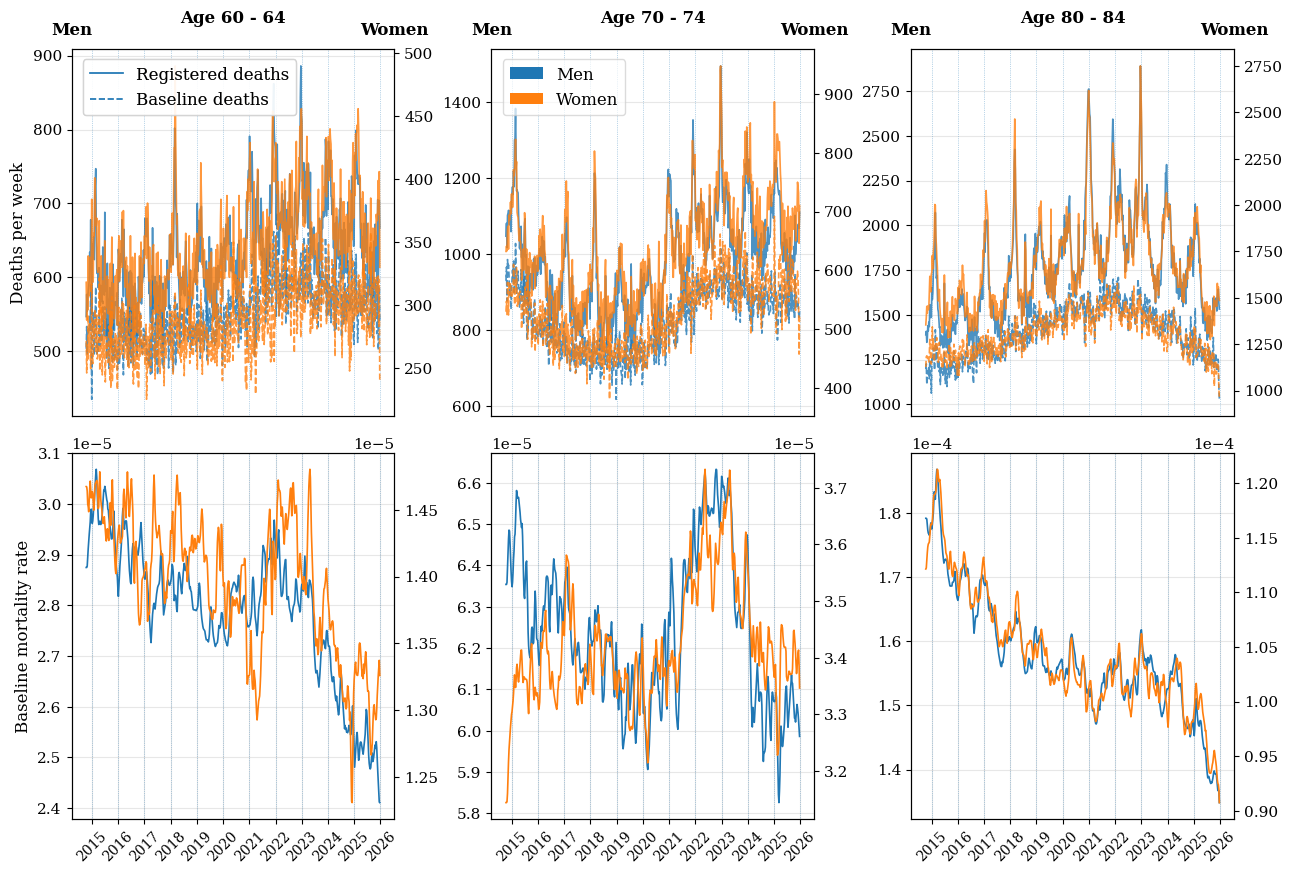

In [6]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ---- year ticks along weekly index ----
days_cumulative = 80 / 7
year_ticks = []
years = list(range(2015, 2027))

for year in years:
    year_ticks.append(days_cumulative)
    days_in_year = 366 if (year % 4 == 0 and (year % 100 != 0 or year % 400 == 0)) else 365
    days_cumulative += days_in_year / 7

age_groups = [7, 9, 11]

fig, ax = plt.subplots(2, 3, figsize=(15, 10))

for idx, age_group in enumerate(age_groups):
    # ---------- top row: weekly deaths ----------
    ax0 = ax[0, idx]

    # men – deaths (left y-axis)
    ax0.plot(
        destatis[:, age_group, 0],
        label="Registered deaths – men",
        color="C0",
        linestyle="-",
        alpha = 0.8,
    )
    ax0.plot(
        (destatis - death_additional_weekly)[:, age_group, 0],
        label="Baseline deaths – men",
        color="C0",
        linestyle="--",
        alpha = 0.8,
    )
    ax0.xaxis.set_visible(False)
    # women – deaths (right y-axis)
    ax0_r = ax0.twinx()
    ax0_r.plot(
        destatis[:, age_group, 1],
        label="Registered deaths – women",
        color="C1",
        linestyle="-",
        alpha = 0.8,
    )
    ax0_r.plot(
        (destatis - death_additional_weekly)[:, age_group, 1],
        label="Baseline deaths – women",
        color="C1",
        linestyle="--",
        alpha = 0.8,
    )

    ax0.text(
        0, 1.03,          # x<0 稍微往外一点，y>1 在轴上方
        "Men",
        transform=ax0.transAxes,
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight='bold',
    )

    # 在右 y 轴正上方写 "Women"
    ax0_r.text(
        1, 1.03,           # x>1 往右一点，y>1 在轴上方
        "Women",
        transform=ax0_r.transAxes,
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight='bold',
    )
    ax0.set_title(f"Age {25 + 5 * age_group} - {29 + 5 * age_group}", fontsize=12, y=1.05)
    ax0.grid(True, which="both", alpha=0.3)

    # ---------- bottom row: baseline mortality rates ----------
    ax1 = ax[1, idx]

    # men – baseline rate (left y-axis)
    ax1.plot(
        model_rate[:, age_group, 0],
        label="Baseline mortality rate – men",
        color="C0",
        linestyle="-",
    )

    # women – baseline rate (right y-axis)
    ax1_r = ax1.twinx()
    ax1_r.plot(
        model_rate[:, age_group, 1],
        label="Baseline mortality rate – women",
        color="C1",
        linestyle="-",
    )

    ax1.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax1_r.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax1.grid(True, which="both", alpha=0.3)

    # x-axis: calendar years for bottom row (shared with top)
    ax1.set_xticks(year_ticks)
    ax1.set_xticklabels(years, rotation=45, fontsize=10)

    # vertical lines at year positions on both rows
    for t in year_ticks:
        ax0.axvline(t, linestyle=":", linewidth=0.5, alpha=0.6)
        ax1.axvline(t, linestyle=":", linewidth=0.5, alpha=0.6)

# ---------- axis labels ----------
ax[0, 0].set_ylabel("Deaths per week")
ax[1, 0].set_ylabel("Baseline mortality rate")

# ---------- common legend for whole figure ----------
custom_lines = [
    Line2D([0], [0], color="C0", linestyle="-"),
    Line2D([0], [0], color="C0", linestyle="--"),
    Patch(facecolor="C0", edgecolor="none"),  
    Patch(facecolor="C1", edgecolor="none"),
]

legend_labels = [
    "Registered deaths",
    "Baseline deaths",
    "Men", 
    "Women",
]


leg1 = fig.legend(
    custom_lines[:2],
    legend_labels[:2],
    loc="upper left",
    bbox_to_anchor=(0.01, 0.995),          # (x, y) in ax[0,0] axes coords
    bbox_transform=ax[0, 0].transAxes,
    frameon=True,
    framealpha=0.7, 
    fontsize=12                     # transparency of the white box
)

# keep leg1 when creating leg2
fig.add_artist(leg1)

# second legend (colors)
leg2 = fig.legend(
    custom_lines[2:],
    legend_labels[2:],
    loc="upper left",
    bbox_to_anchor=(0.01, 0.995),
    bbox_transform=ax[0, 1].transAxes,
    frameon=True,
    framealpha=0.7,
    fontsize=12
)

plt.subplots_adjust(wspace=0.30, hspace=0.10)
# plt.savefig('death_rates.svg', bbox_inches='tight')
# plt.savefig('death_rates.png', bbox_inches='tight', dpi=300)
plt.show()


## Supplementary Figure 9: All age groups

This extended panel applies the same registered-versus-baseline comparison to all modeled age groups, including the aggregated 0-30 and open-ended 95+ categories.

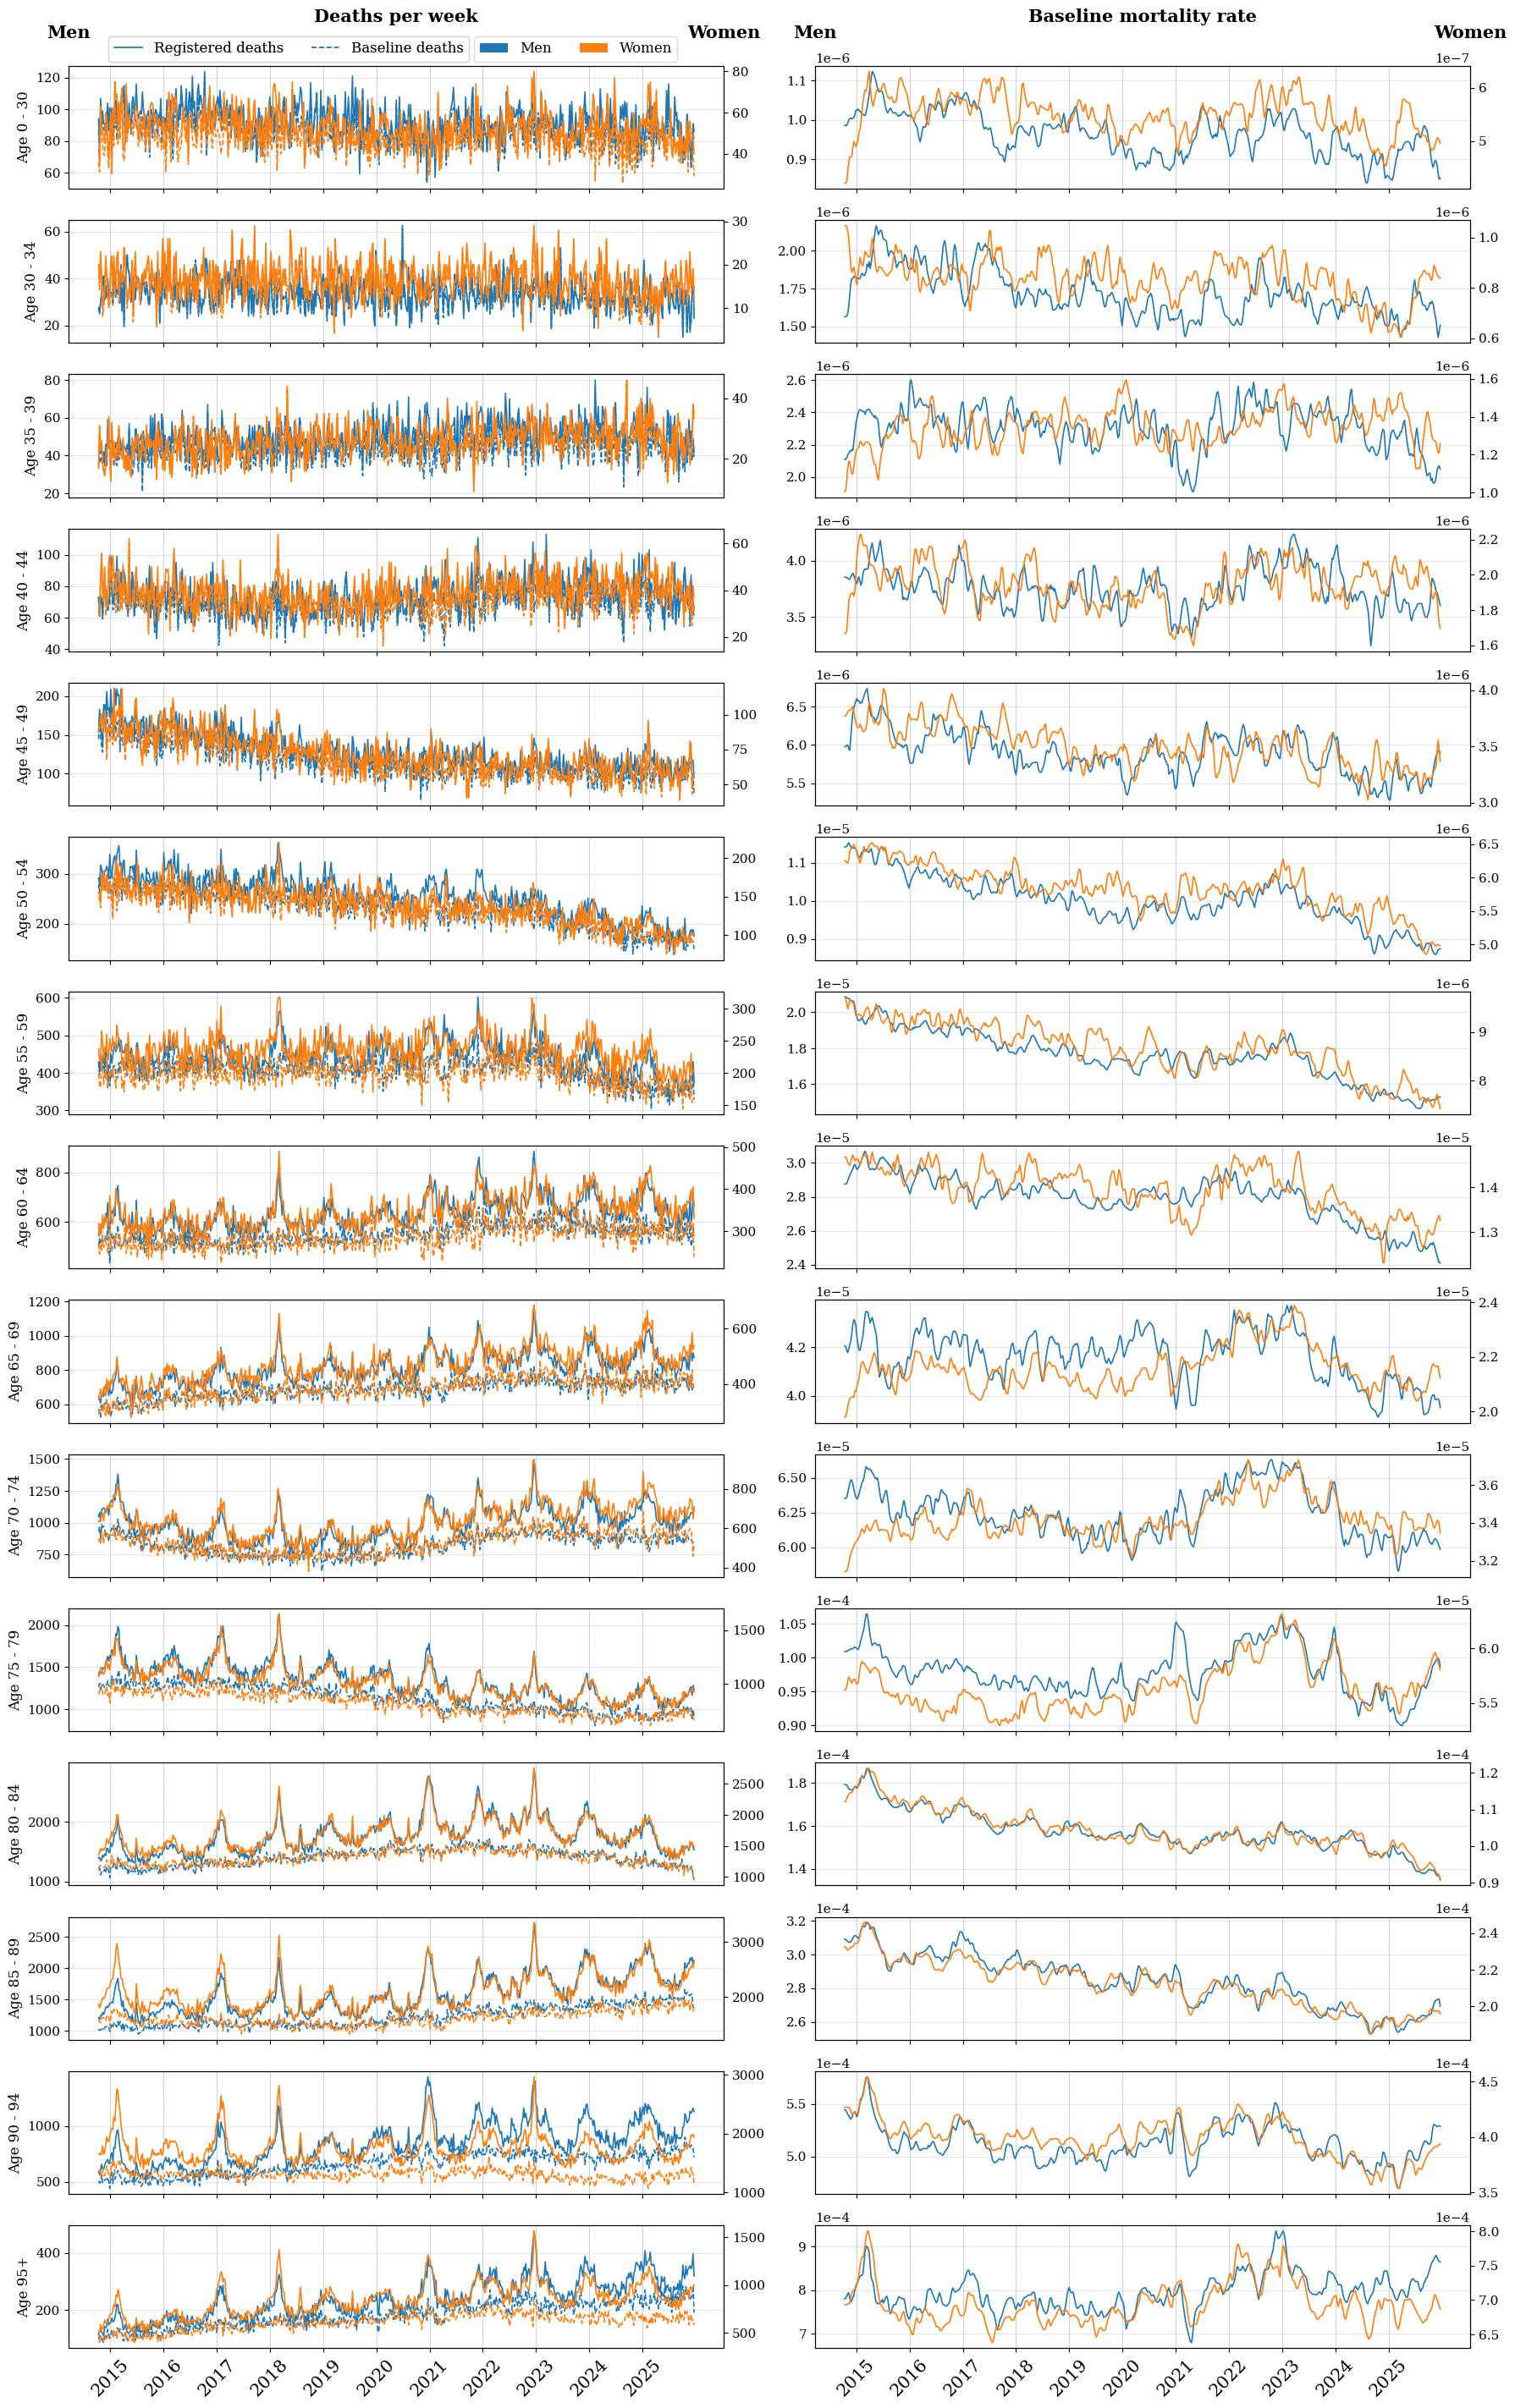

In [7]:
# ---- year ticks along weekly index ----
days_cumulative = 80 / 7
year_ticks = []
years = list(range(2015, 2026))

for year in years:
    year_ticks.append(days_cumulative)
    days_in_year = 366 if (year % 4 == 0 and (year % 100 != 0 or year % 400 == 0)) else 365
    days_cumulative += days_in_year / 7

age_groups = np.arange(0,15)

# 现在：3 行 × 2 列
fig, ax = plt.subplots(len(age_groups), 2, figsize=(18, 2 * len(age_groups)), sharex=True)

for i, age_group in enumerate(age_groups):
    # ---------- 左列：weekly deaths ----------
    ax_death = ax[i, 0]

    # women – deaths (right y-axis)
    ax_death_r = ax_death.twinx()
    ax_death_r.plot(
        destatis[:, age_group, 1],
        label="Registered deaths – women",
        color="C1",
        linestyle="-",
    )
    ax_death_r.plot(
        (destatis - death_additional_weekly)[:, age_group, 1],
        label="Baseline deaths – women",
        color="C1",
        linestyle="--",
    )

    # men – deaths (left y-axis)
    ax_death.plot(
        destatis[:, age_group, 0],
        label="Registered deaths – men",
        color="C0",
        linestyle="-",
    )
    ax_death.plot(
        (destatis - death_additional_weekly)[:, age_group, 0],
        label="Baseline deaths – men",
        color="C0",
        linestyle="--",
    )

    # 每一行在左图写年龄段
    if i == 0:
        ax_death.set_ylabel(f"Age 0 - 30", fontsize=12)
    elif i == 14:
        ax_death.set_ylabel(f"Age 95+", fontsize=12)
    else:
        ax_death.set_ylabel(f"Age {25 + 5 * age_group} - {29 + 5 * age_group}", fontsize=12)

    ax_death.grid(True, which="both", alpha=0.3)

    # ---------- 右列：baseline mortality rates ----------
    ax_rate = ax[i, 1]

    # men – baseline rate (left y-axis)
    ax_rate.plot(
        model_rate[:, age_group, 0],
        label="Baseline mortality rate – men",
        color="C0",
        linestyle="-",
    )

    # women – baseline rate (right y-axis)
    ax_rate_r = ax_rate.twinx()
    ax_rate_r.plot(
        model_rate[:, age_group, 1],
        label="Baseline mortality rate – women",
        color="C1",
        linestyle="-",
    )

    ax_rate.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax_rate_r.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax_rate.grid(True, which="both", alpha=0.3)

    # 垂直年线：两列都画
    for t in year_ticks:
        ax_death.axvline(t, linestyle=":", linewidth=0.5, alpha=0.6)
        ax_rate.axvline(t, linestyle=":", linewidth=0.5, alpha=0.6)

    # 在第一行图上方标 Men / Women
    if i == 0:
        ax_death.text(
            0.0, 1.2,
            "Men",
            transform=ax_death.transAxes,
            ha="center",
            va="bottom",
            fontsize=15,
            fontweight="bold",
        )
        ax_death_r.text(
            1.0, 1.2,
            "Women",
            transform=ax_death_r.transAxes,
            ha="center",
            va="bottom",
            fontsize=15,
            fontweight="bold",
        )
        ax_rate.text(
            0.0, 1.2,
            "Men",
            transform=ax_rate.transAxes,
            ha="center",
            va="bottom",
            fontsize=15,
            fontweight="bold",
        )
        ax_rate_r.text(
            1.0, 1.2,
            "Women",
            transform=ax_rate_r.transAxes,
            ha="center",
            va="bottom",
            fontsize=15,
            fontweight="bold",
        )

# 只在最后一行设置 x tick 和 label（共享 x）
for j in range(2):
    ax[-1, j].set_xticks(year_ticks)
    ax[-1, j].set_xticklabels(years, rotation=45, fontsize=15)

# 列标题：左=Deaths per week，右=Baseline mortality rate
ax[0, 0].set_title("Deaths per week", fontsize=15, y=1.3)
ax[0, 1].set_title("Baseline mortality rate", fontsize=15, y=1.3)

# ---------- common legend ----------
custom_lines = [
    Line2D([0], [0], color="C0", linestyle="-"),   # Registered deaths
    Line2D([0], [0], color="C0", linestyle="--"),  # Baseline deaths
    Patch(facecolor="C0", edgecolor="none"),  
    Patch(facecolor="C1", edgecolor="none"),
]

legend_labels = [
    "Registered deaths",
    "Baseline deaths",
    "Men",
    "Women",
]

# first legend (line styles) – anchored to the first axes position
leg1 = fig.legend(
    custom_lines[:2],
    legend_labels[:2],
    loc="upper left",
    bbox_to_anchor=(0.05, 1.3),          # (x, y) in ax[0,0] axes coords
    bbox_transform=ax[0, 0].transAxes,
    ncol=2,
    frameon=True,
    framealpha=0.7, 
    fontsize=12                     # transparency of the white box
)

# keep leg1 when creating leg2
fig.add_artist(leg1)

# second legend (colors)
leg2 = fig.legend(
    custom_lines[2:],
    legend_labels[2:],
    loc="upper right",
    bbox_to_anchor=(0.94, 1.3),
    bbox_transform=ax[0, 0].transAxes,
    ncol=2,
    frameon=True,
    framealpha=0.7,
    fontsize=12
)
plt.subplots_adjust(wspace=0.3, hspace=0.25)
plt.tight_layout(rect=[0, 0, 1, 0.95])
# plt.savefig('death_baseline_all.png', bbox_inches='tight', dpi=300)
plt.show()
